# PageRank on the arXiv co-authorship graph

**Algorithms for Massive Data**, Master in Data Science for Economics, Università degli Studi di Milano

Project 3: Link analysis

Laura Shulbayeva (51204A)

The notebook builds a co-authorship graph from the arXiv metadata snapshot, where two authors are linked if they wrote at least one paper together, and ranks authors with PageRank implemented on Spark RDDs. The result is validated against networkx, tested for its sensitivity to the damping factor and to the pre-processing threshold, extended to topic-sensitive PageRank, and the cost of the computation is measured on samples of increasing size and on the whole dataset.

## Setup

Spark runs in local mode using all available cores. In local mode the driver also runs the executors, so it is given 8 GB of the memory of the Colab machine. To run the same code on a cluster, the `master` parameter has to point to the cluster and the data file has to be stored on a distributed file system such as HDFS.

Running the whole notebook takes about two and a half hours on a free Colab instance. Most of the time is spent in the PageRank computations: the main run, the comparison of three values of β, the topic-sensitive variant, the comparison of two thresholds and the scalability experiments, including the run on the whole dataset.

In [15]:
!pip install -q pyspark==4.0.5

from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .master("local[*]")
         .appName("arxiv-pagerank")
         .config("spark.driver.memory", "8g")
         .getOrCreate())
sc = spark.sparkContext
spark

## Dataset

The project uses the arXiv metadata snapshot published on Kaggle (`Cornell-University/arxiv`, CC0 Public Domain). Each record describes one paper. The parsed list of authors is used to build the graph and the arXiv categories are used for the topic-sensitive variant of PageRank; the identifier and the raw author string are kept only to inspect the records.

The dataset is updated regularly, so a later download contains more papers and the counts and rankings may differ slightly from the ones shown here.

To run the notebook, replace the `"xxxxxx"` strings below with your Kaggle username and API key.

In [38]:
import os

os.environ['KAGGLE_USERNAME'] = "xxxxxx"
os.environ['KAGGLE_KEY'] = "xxxxxx"

if not os.path.exists("arxiv-metadata-oai-snapshot.json"):
    !kaggle datasets download -d Cornell-University/arxiv
    !unzip -o -q arxiv.zip
    !rm arxiv.zip
!ls -lh

total 5.4G
-rw-r--r-- 1 root root 5.4G Nov 15 00:54 arxiv-metadata-oai-snapshot.json
drwxr-xr-x 1 root root 4.0K Oct 26 22:18 sample_data


## Configuration

The main parameters are set here; the experiments in the later sections define their own additional parameters (topic, alternative threshold, sample sizes) in their cells.

- `SAMPLE_FRACTION`: fraction of papers used. 1.0 means the whole snapshot; smaller values take a random sample. The analysis uses a 5% sample: running PageRank to convergence on the whole dataset takes about 3.4 hours on a free Colab instance, as measured in the scalability section.
- `SEED`: random seed for sampling, so results can be reproduced.
- `MAX_AUTHORS`: papers with more authors than this are excluded when building the graph (justified below).
- `BETA`: damping factor of PageRank. With probability `BETA` the random surfer follows a link, otherwise it teleports to a random node.
- `MAX_ITER`, `TOL`: PageRank stops when the L1 distance between two consecutive rank vectors is below `TOL`, or after `MAX_ITER` iterations.

In [17]:
DATA_PATH = "arxiv-metadata-oai-snapshot.json"
SAMPLE_FRACTION = 0.05
SEED = 42
MAX_AUTHORS = 30

BETA = 0.85
MAX_ITER = 100
TOL = 1e-6

## Loading the data

The file is in JSON Lines format, one paper per line. Instead of letting Spark infer the schema, which would require an extra pass over 5 GB of data, we declare only the fields we need. Fields such as the abstract, the comments and the version history are not converted into columns, which reduces memory use when the data is cached. Loading is wrapped in a function because the scalability section loads samples of different sizes.

The sample is drawn over papers, not over authors: each paper is kept independently with probability `SAMPLE_FRACTION`, so the sample size is close to, but not exactly, 5% of the snapshot. Each sampled author keeps only part of his or her papers and co-authors, so the graph built on a sample is sparser than the full co-authorship graph, and the rankings obtained on it approximate those of the whole dataset rather than reproducing them.

In [39]:
from pyspark.sql.types import StructType, StructField, StringType, ArrayType

schema = StructType([
    StructField("id", StringType()),
    StructField("authors", StringType()),
    StructField("authors_parsed", ArrayType(ArrayType(StringType()))),
    StructField("categories", StringType()),
])

def load_papers(fraction):
    df = spark.read.schema(schema).json(DATA_PATH)
    return df if fraction >= 1.0 else df.sample(fraction=fraction, seed=SEED)

papers = load_papers(SAMPLE_FRACTION).cache()
print("Papers:", papers.count())
papers.show(5, truncate=60)

Papers: 163125
+---------+------------------------------------------------------------+------------------------------------------------------------+--------------+
|       id|                                                     authors|                                              authors_parsed|    categories|
+---------+------------------------------------------------------------+------------------------------------------------------------+--------------+
|0704.0017|Nceba Mhlahlo, David H. Buckley, Vikram S. Dhillon, Steve...|[[Mhlahlo, Nceba, ], [Buckley, David H., ], [Dhillon, Vik...|      astro-ph|
|0704.0080|                      Dean E. McLaughlin and S. Michael Fall|             [[McLaughlin, Dean E., ], [Fall, S. Michael, ]]|      astro-ph|
|0704.0091|                                              Ashot Minasyan|                                       [[Minasyan, Ashot, ]]|       math.GR|
|0704.0106|            Andreas Schafer, Xin-Nian Wang and Ben-Wei Zhang|[[Schafer, Andreas,

## Number of authors per paper

A paper with k authors produces k(k-1) directed edges in the co-authorship graph, so the distribution of k matters for the size of the graph.

In [19]:
from pyspark.sql import functions as F

n_authors = papers.select(F.size("authors_parsed").alias("n"))
n_authors.describe().show()

for k in [1, 2, 5, 10, 30, 100, 1000]:
    print(f"papers with more than {k} authors:", n_authors.filter(F.col("n") > k).count())

+-------+-----------------+
|summary|                n|
+-------+-----------------+
|  count|           163125|
|   mean| 4.74760459770115|
| stddev|23.76015363308009|
|    min|                1|
|    max|             1803|
+-------+-----------------+

papers with more than 1 authors: 133901
papers with more than 2 authors: 95889
papers with more than 5 authors: 27827
papers with more than 10 authors: 6750
papers with more than 30 authors: 1145
papers with more than 100 authors: 370
papers with more than 1000 authors: 24


Most papers have few authors, but the tail is long: the largest paper in the sample has 1803 authors. The next cell measures how many directed edges each group of papers contributes, to choose the value of `MAX_AUTHORS`. These counts are computed before removing duplicates: two authors who wrote several papers together are counted once per paper here, but give a single edge in the final graph.

In [20]:
n_papers = n_authors.count()
edges_per_paper = n_authors.withColumn("edges", F.col("n") * (F.col("n") - 1))
total = edges_per_paper.agg(F.sum("edges")).first()[0]
print(f"all papers: {total:,} directed edges")

for t in [10, 20, 30, 50, 100]:
    kept = edges_per_paper.filter(F.col("n") <= t)
    papers_kept = kept.count()
    edges_kept = kept.agg(F.sum("edges")).first()[0]
    print(f"max {t:>3} authors: {papers_kept / n_papers:.2%} of papers, "
          f"{edges_kept:,} edges ({edges_kept / total:.2%} of all)")

all papers: 94,993,166 directed edges
max  10 authors: 95.86% of papers, 1,781,920 edges (1.88% of all)
max  20 authors: 98.76% of papers, 2,640,772 edges (2.78% of all)
max  30 authors: 99.30% of papers, 3,168,506 edges (3.34% of all)
max  50 authors: 99.59% of papers, 3,856,360 edges (4.06% of all)
max 100 authors: 99.77% of papers, 5,331,632 edges (5.61% of all)


## Pre-processing: the co-authorship graph

Papers with more than `MAX_AUTHORS` authors are excluded. On a 5% sample they are 0.7% of the papers but generate about 97% of all directed edges, because a paper with k authors produces k(k-1) edges. Most of them come from large collaborations, where co-authorship does not necessarily reflect a direct working relationship.

Authors are identified by a normalized name: first name and last name, lowercased, with dots, LaTeX accent markup and repeated spaces removed. This does not solve name ambiguity: two different people with the same name are merged, and the same person written in two ways ("D. Buckley" and "David H. Buckley", or "Cédric" and the LaTeX form `C\'edric`, which becomes "cedric") is split. The Kaggle metadata contain no author identifiers, so this limitation cannot be removed within the dataset; it could be addressed by linking papers to an external source with disambiguated authors, such as OpenAlex.

Each pair of co-authors gives two directed edges (A→B and B→A), and duplicates are removed: an edge exists if two authors co-authored at least one paper. In MapReduce terms, the map step (`flatMap`) emits the pairs of co-authors of each paper and the reduce step (`distinct`) removes the duplicates. Graph construction is wrapped in a function because the graph is rebuilt later with a different threshold and on samples of different sizes.

Authors who appear only in single-author papers, or only in papers excluded by `MAX_AUTHORS`, have no co-authorship edges and are not part of the graph. PageRank is therefore computed only for authors with at least one co-author.

In [32]:
import re
from itertools import permutations

def author_key(parts):
    last = parts[0] if len(parts) > 0 else ""
    first = parts[1] if len(parts) > 1 else ""
    name = f"{first} {last}".lower()
    name = re.sub(r"[\\{}'\"`^~.]", "", name)
    return re.sub(r"\s+", " ", name).strip()

def coauthor_edges(authors_parsed):
    names = {author_key(p) for p in authors_parsed} - {""}
    return permutations(names, 2)

def build_edges(papers, max_authors):
    return (papers.select("authors_parsed").rdd
            .map(lambda row: row.authors_parsed)
            .filter(lambda a: a is not None and 2 <= len(a) <= max_authors)
            .flatMap(coauthor_edges)
            .distinct())

edges = build_edges(papers, MAX_AUTHORS).cache()

nodes = edges.keys().distinct()
print("Authors (nodes):", nodes.count())
print("Directed edges:", edges.count())
edges.take(10)

Authors (nodes): 340220
Directed edges: 2932050


[('steven b potter', 'vikram s dhillon'),
 ('tomasz plewa', 'christopher w mauche'),
 ('s gutierrez-oliva', 'p k chattaraj'),
 ('m mugrauer', 't roell'),
 ('gilles de france', 'cédric simenel'),
 ('eisuke abe', 'shingo katsumoto'),
 ('f sprenger', 'e w schmidt'),
 ('s schippers', 's böhm'),
 ('mercedes rosas', 'emmanuel briand'),
 ('s j smartt', 'a herrero')]

## PageRank

The graph is stored as adjacency lists, pairs (author, list of co-authors), obtained from the edges with `groupByKey`. The implementation follows the course notebook on PageRank in Spark: one iteration is the product between the transition matrix and the rank vector, written in MapReduce style (RU 2.3.1). Each author sends `rank / out_degree` to every co-author (map), and the contributions received by each author are summed (reduce). Taxation is then applied (RU 5.1.5):

$$v' = \beta M v + (1 - \beta)\, e / N$$

where $M$ is the transition matrix ($M_{ij} = 1/\deg(j)$ if $i$ and $j$ are co-authors, 0 otherwise), $N$ is the number of authors and $e$ is the vector of $N$ ones.

The difference from the course notebook is the rank vector. There it is a numpy array kept on the driver and collected at every iteration, which works when the vector fits in memory. Here the rank vector is itself an RDD, joined with the adjacency lists, so neither the matrix nor the vector has to fit on a single machine.

The co-authorship graph has no dead ends, since every author in the graph has at least one co-author, so the total rank stays equal to 1. The graph is split into many disconnected components; taxation lets the random surfer leave any of them, so the power iteration converges to a unique vector.

The adjacency lists and the rank vector are hash-partitioned in the same way, so joining them does not require a shuffle. The rank RDD is checkpointed every 10 iterations to keep its lineage short. The function also accepts an optional set of authors to which the random surfer teleports; by default it is the whole graph, and a restricted set is used later for topic-sensitive PageRank.

In [29]:
import time
from operator import add

NUM_PARTITIONS = sc.defaultParallelism * 4

def pagerank(links, n, beta=BETA, max_iter=MAX_ITER, tol=TOL, teleport=None):
    # teleport: broadcast set of nodes for topic-sensitive PageRank; None means all nodes
    if teleport is None:
        tax = lambda name: (1 - beta) / n
    else:
        size = len(teleport.value)
        tax = lambda name: (1 - beta) / size if name in teleport.value else 0.0

    ranks = links.mapValues(lambda _: 1.0 / n)
    history = []
    for i in range(1, max_iter + 1):
        contribs = links.join(ranks).flatMap(
            lambda x: [(dst, x[1][1] / len(x[1][0])) for dst in x[1][0]])
        new_ranks = (contribs.reduceByKey(add, NUM_PARTITIONS)
                     .map(lambda x: (x[0], beta * x[1] + tax(x[0])),
                          preservesPartitioning=True)
                     .cache())
        if i % 10 == 0:
            new_ranks.localCheckpoint()
        diff = new_ranks.join(ranks).values().map(lambda r: abs(r[0] - r[1])).sum()
        ranks.unpersist()
        ranks = new_ranks
        history.append(diff)
        if i % 10 == 0:
            print(f"iteration {i}: L1 change {diff:.2e}")
        if diff < tol:
            break
    return ranks, history

links = edges.groupByKey(NUM_PARTITIONS).mapValues(list).cache()
n = links.count()

start = time.time()
ranks, history = pagerank(links, n)
elapsed = time.time() - start

print(f"\nNodes: {n}")
print(f"Iterations: {len(history)}, final L1 change: {history[-1]:.2e}")
print(f"Time: {elapsed:.0f} s")
print(f"Sum of ranks: {ranks.values().sum():.6f}")

iteration 10: L1 change 3.46e-03
iteration 20: L1 change 4.05e-04
iteration 30: L1 change 6.50e-05
iteration 40: L1 change 1.14e-05
iteration 50: L1 change 2.09e-06

Nodes: 340220
Iterations: 55, final L1 change: 9.03e-07
Time: 1073 s
Sum of ranks: 1.000000


## Results

The L1 change between consecutive rank vectors decreases geometrically. The convergence analysis gives β as an upper bound on the rate: with taxation, every eigenvalue of the matrix other than the principal one has modulus at most β, so the error shrinks at least as fast as $\beta^t$. In the first iterations the decrease is faster; in the last ones the observed rate, printed below, is 0.845, close to β = 0.85. The bound is reached because the graph contains many small bipartite components, for example an author who wrote separate two-author papers with a few co-authors, none of whom has other collaborations. The transition matrix of such a component has eigenvalue −1, which becomes −β after taxation.

The table lists the top authors by PageRank, together with their degree (number of distinct co-authors). PageRank is shown multiplied by N, so that 1 corresponds to the value every author would get under the uniform distribution.

observed decrease per iteration: 0.845 (β = 0.85)


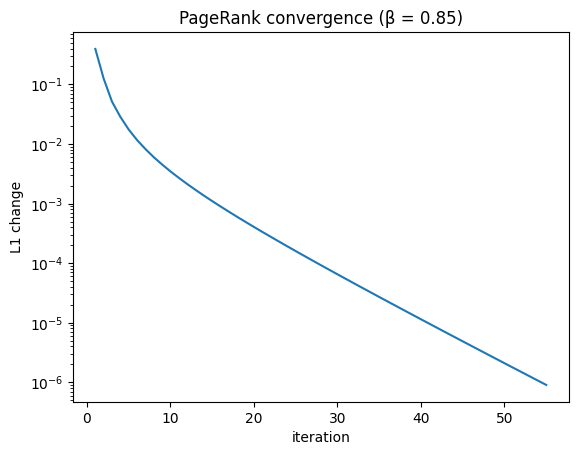

,author,PageRank × N,co-authors
0,takashi taniguchi,69.701251,1086
1,kenji watanabe,66.799960,1049
2,yang liu,60.960461,768
3,yu zhang,45.943799,608
4,wei wang,44.916947,549
5,wei zhang,36.492228,471
6,yu liu,35.644331,490
7,xin wang,34.631028,484
8,xiang li,34.484375,461
9,hao chen,34.119837,449


In [24]:
import matplotlib.pyplot as plt
import pandas as pd

rate = (history[-1] / history[-11]) ** (1 / 10)
print(f"observed decrease per iteration: {rate:.3f} (β = {BETA})")

plt.semilogy(range(1, len(history) + 1), history)
plt.xlabel("iteration")
plt.ylabel("L1 change")
plt.title(f"PageRank convergence (β = {BETA})")
plt.show()

degree = links.mapValues(len)
top = ranks.takeOrdered(20, key=lambda x: -x[1])
top_names = {name for name, _ in top}
top_degree = dict(degree.filter(lambda x: x[0] in top_names).collect())
base = dict(ranks.collect())

pd.DataFrame(
    [(name, rank * n, top_degree[name]) for name, rank in top],
    columns=["author", "PageRank × N", "co-authors"],
)

The first two positions are held by Takashi Taniguchi and Kenji Watanabe, who grow the hexagonal boron nitride crystals used by many laboratories working on graphene and other two-dimensional materials, and are therefore co-authors of a very large number of papers in that field. Their position reflects a real feature of the collaboration network.

The other 18 names in the top 20 are all common Chinese names. These nodes probably merge several different researchers, as discussed in the pre-processing section, so their degree and their PageRank are inflated. Separating them would require entity disambiguation techniques such as those seen in the course (similarity of affiliations, co-authors or topics), which are outside the scope of this project.

## PageRank and degree

On a connected undirected graph, the stationary distribution of the random walk without taxation is proportional to the degree of each node. With taxation and many connected components this holds only approximately and only inside each component: every component keeps a share of the total rank proportional to its size, and this share is then divided among its nodes roughly by degree.

The correlation is measured with Spearman's rank correlation, which treats all positions equally, and with the weighted Kendall's τ, which gives more importance to agreement at the top of the two rankings.

In [41]:
from scipy.stats import spearmanr, weightedtau

pairs = ranks.join(degree).values().collect()
pr_values = [p for p, _ in pairs]
deg_values = [d for _, d in pairs]

print(f"Spearman correlation: {spearmanr(pr_values, deg_values)[0]:.3f}")
print(f"weighted Kendall tau:  {weightedtau(pr_values, deg_values)[0]:.3f}")

top_deg = degree.takeOrdered(20, key=lambda x: -x[1])
overlap = top_names & {name for name, _ in top_deg}
print(f"authors in both top-20 lists: {len(overlap)}")
print(f"authors with at most 3 co-authors: {sum(d <= 3 for d in deg_values) / len(deg_values):.1%}")

Spearman correlation: 0.554
weighted Kendall tau:  0.877
authors in both top-20 lists: 18
authors with at most 3 co-authors: 36.2%


The two measures disagree. The weighted τ is high and 18 of the top-20 authors by PageRank are also in the top-20 by degree: among the most connected authors, PageRank mostly follows the number of co-authors. Spearman's correlation is much lower because it gives the same weight to every author, and many authors have few co-authors: 36.2% have at most three. Among authors with the same small degree, PageRank varies widely depending on the component they belong to. An author in an isolated pair has PageRank × N = 1, the uniform value. An author whose only co-author is Takashi Taniguchi receives 0.85 · 69.7 / 1086 + 0.15 ≈ 0.2. Both have degree 1, but their PageRank differs by a factor of five. Differences of this kind reorder a large part of the ranking without affecting its top.

## Sensitivity to β

β sets the balance between following links and teleporting. A smaller β moves the ranks towards the uniform distribution and makes the iteration converge faster, since the error shrinks roughly as $\beta^t$. A larger β gives more weight to the graph structure.

PageRank is recomputed with β = 0.8 (the value used in the course) and β = 0.9, with the same tolerance as the main run, and compared with the β = 0.85 result. For each value we report the number of iterations needed to converge, how many of the top-20 authors coincide with the β = 0.85 ranking, and the weighted Kendall's τ between the full rankings.

In [26]:
beta_runs = {BETA: (ranks, history)}
for b in [0.8, 0.9]:
    start = time.time()
    beta_runs[b] = pagerank(links, n, beta=b, max_iter=200)
    print(f"β = {b}: {len(beta_runs[b][1])} iterations, {time.time() - start:.0f} s")

names = list(base)

rows = []
for b in sorted(beta_runs):
    r, h = beta_runs[b]
    values = dict(r.collect())
    top_b = {a for a, _ in r.takeOrdered(20, key=lambda x: -x[1])}
    tau = weightedtau([base[a] for a in names], [values[a] for a in names])[0]
    rows.append((b, len(h), len(top_b & top_names), tau))

pd.DataFrame(rows, columns=["β", "iterations", "top-20 shared with β=0.85",
                            "weighted τ vs β=0.85"])

iteration 10: L1 change 1.89e-03
iteration 20: L1 change 1.20e-04
iteration 30: L1 change 1.05e-05
iteration 40: L1 change 1.01e-06
β = 0.8: 41 iterations, 842 s
iteration 10: L1 change 6.14e-03
iteration 20: L1 change 1.27e-03
iteration 30: L1 change 3.61e-04
iteration 40: L1 change 1.12e-04
iteration 50: L1 change 3.65e-05
iteration 60: L1 change 1.21e-05
iteration 70: L1 change 4.07e-06
iteration 80: L1 change 1.38e-06
β = 0.9: 84 iterations, 1674 s


,β,iterations,top-20 shared with β=0.85,weighted τ vs β=0.85
0,0.80,41,20,0.992133
1,0.85,55,20,1.000000
2,0.90,84,19,0.989806


In [27]:
for b in sorted(beta_runs):
    h = beta_runs[b][1]
    print(f"β = {b}: observed decrease per iteration {(h[-1] / h[-11]) ** (1 / 10):.3f}")

β = 0.8: observed decrease per iteration 0.791
β = 0.85: observed decrease per iteration 0.845
β = 0.9: observed decrease per iteration 0.898


The ranking is stable with respect to β: the top 20 is the same for β = 0.8 and β = 0.85 and differs by one author for β = 0.9, and the weighted τ between the full rankings is above 0.99 in both cases.

β mainly affects the cost of the computation. In each run the final rate of decrease is close to β (0.791, 0.845 and 0.898). Since the error shrinks as $\beta^t$, the number of iterations needed to reach a fixed tolerance is approximately proportional to $1 / |\log \beta|$. Starting from the 55 iterations needed with β = 0.85, this predicts about 40 iterations for β = 0.8 and 85 for β = 0.9; the observed values are 41 and 84. The time of one iteration does not depend on β (between 19.5 and 20.5 s in the three runs), so the running time grows in the same proportion.

## Validation

The Spark implementation is compared with the PageRank function of networkx, run on the same graph with the same β and a much smaller tolerance, so that its result can serve as an accurate reference. networkx keeps the whole graph in the memory of a single machine: this is feasible for the 5% sample, while the whole dataset has 37.5 million directed edges. Here it is used only to check the correctness of the distributed implementation.

In [28]:
import networkx as nx

G = nx.Graph()
G.add_edges_from(edges.filter(lambda e: e[0] < e[1]).collect())
nx_pr = nx.pagerank(G, alpha=BETA, tol=1e-12, max_iter=1000)

diffs = [abs(base[a] - nx_pr[a]) for a in base]
print(f"nodes: Spark {len(base)}, networkx {G.number_of_nodes()}")
print(f"max absolute difference: {max(diffs):.2e}")
print(f"L1 difference: {sum(diffs):.2e}")

nx_top = {a for a, _ in sorted(nx_pr.items(), key=lambda x: -x[1])[:20]}
print(f"top-20 shared: {len(nx_top & top_names)}")

nodes: Spark 340220, networkx 340220
max absolute difference: 4.42e-10
L1 difference: 8.48e-07
top-20 shared: 20


The two implementations agree. The largest difference for a single author is about 4·10⁻¹⁰, while the average value is 1/N ≈ 3·10⁻⁶, and the L1 difference between the two vectors is of the same order as the stopping tolerance of the Spark implementation. The top 20 is identical.

## Topic-sensitive PageRank

In topic-sensitive PageRank (RU 5.3) the random surfer teleports only to a set S of nodes related to a topic, instead of to any node:

$$v' = \beta M v + (1 - \beta)\, e_S / |S|$$

where $e_S$ has entries equal to 1 for the authors in S and 0 elsewhere. The topic chosen here is mathematics: S contains the authors of at least one paper whose primary arXiv category (the first one listed) belongs to the `math` archive. The ranking then favours authors who are well connected to mathematicians, not only authors with many co-authors in any field.

Since the graph has no dead ends, the total rank still sums to 1. Connected components of the graph that contain no author of S receive no teleportation and no rank from outside, so at every iteration their rank is multiplied by β and tends to zero.

In [30]:
TOPIC = "math"

topic_authors = (papers.select("authors_parsed", "categories").rdd
                 .filter(lambda r: r.authors_parsed is not None and r.categories
                         and 2 <= len(r.authors_parsed) <= MAX_AUTHORS
                         and r.categories.split()[0].split(".")[0] == TOPIC)
                 .flatMap(lambda r: [author_key(p) for p in r.authors_parsed])
                 .distinct()
                 .collect())
teleport_set = sc.broadcast(set(topic_authors) & set(base))
print(f"authors in the teleport set: {len(teleport_set.value)} of {n}")

start = time.time()
topic_ranks, topic_history = pagerank(links, n, teleport=teleport_set)
print(f"Iterations: {len(topic_history)}, time: {time.time() - start:.0f} s")
print(f"Sum of ranks: {topic_ranks.values().sum():.6f}")

authors in the teleport set: 38192 of 340220
iteration 10: L1 change 4.60e-02
iteration 20: L1 change 8.26e-03
iteration 30: L1 change 1.53e-03
iteration 40: L1 change 2.88e-04
iteration 50: L1 change 5.45e-05
iteration 60: L1 change 1.04e-05
iteration 70: L1 change 1.99e-06
Iterations: 75, time: 1475 s
Sum of ranks: 1.000000


In [31]:
rate = (topic_history[-1] / topic_history[-11]) ** (1 / 10)
print(f"observed decrease per iteration: {rate:.3f}")

general_pos = {a: i + 1 for i, a in enumerate(sorted(base, key=base.get, reverse=True))}
size = len(teleport_set.value)

topic_top = topic_ranks.takeOrdered(20, key=lambda x: -x[1])
topic_names = {a for a, _ in topic_top}
topic_degree = dict(degree.filter(lambda x: x[0] in topic_names).collect())

s_mass = topic_ranks.filter(lambda x: x[0] in teleport_set.value).values().sum()
print(f"rank held by authors in S: {s_mass:.3f}")
print(f"top-20 shared with general PageRank: {len(topic_names & top_names)}")

pd.DataFrame(
    [(a, r * size, general_pos[a], topic_degree[a], a in teleport_set.value)
     for a, r in topic_top],
    columns=["author", "PageRank × |S|", "general rank", "co-authors", "in S"],
)

observed decrease per iteration: 0.848
rank held by authors in S: 0.817
top-20 shared with general PageRank: 3


,author,PageRank × |S|,general rank,co-authors,in S
0,saharon shelah,11.107116,184,34,True
1,steven j miller,9.203215,239,73,True
2,delfim f m torres,7.385691,336,25,True
3,alexander gasnikov,5.472278,505,45,True
4,wei wang,4.856993,5,549,True
5,yang liu,4.708636,3,768,True
6,bernd sturmfels,4.484075,1002,29,True
7,indranil biswas,4.431401,726,28,True
8,taras banakh,4.287516,2069,12,True
9,kathrin bringmann,4.065393,1933,17,True


With teleportation restricted to the 38,192 authors of mathematics papers (11% of the graph), these authors hold 82% of the total rank, and all of the top 20 belong to S. Only 3 of the top-20 authors of the general ranking remain in the top 20, and all three are common names: "wei wang", "yang liu" and "lei zhang". The other 17 are authors of mathematics papers, such as Saharon Shelah, Steven J. Miller and Bernd Sturmfels, whose position in the general ranking ranges from 184 to 2833. They have between 11 and 73 co-authors in the sample, so plain PageRank, which in this graph largely follows the degree, does not distinguish them from many other authors.

The three common names are merged nodes that include at least one author of a mathematics paper, so they belong to S, and they also receive rank from hundreds of co-authors. The name ambiguity therefore affects the topic-sensitive ranking as well.

Convergence takes 75 iterations instead of 55. Components with no author of S receive no teleportation, so at every iteration their rank is simply multiplied by β. Starting from the uniform vector, they hold most of the rank, and this rank decreases only as $\beta^t$, which gives larger changes for the same rate of decrease (0.848, again close to β). Starting from $e_S / |S|$ instead of the uniform vector would avoid this and reduce the number of iterations.

## Sensitivity to MAX_AUTHORS

The threshold of 30 authors was chosen from the edge counts above. To check how much it affects the result, the graph is rebuilt with a threshold of 50 and PageRank is recomputed. Every author of the original graph is also in the new one, so the two rankings can be compared on the same set of authors.

In [33]:
# the β variants are no longer needed; free their memory
for b in (0.8, 0.9):
    beta_runs[b][0].unpersist()

ALT_MAX_AUTHORS = 50

links_alt = (build_edges(papers, ALT_MAX_AUTHORS)
             .groupByKey(NUM_PARTITIONS).mapValues(list).cache())
n_alt = links_alt.count()
print(f"MAX_AUTHORS = {ALT_MAX_AUTHORS}: {n_alt} authors, "
      f"{links_alt.values().map(len).sum()} directed edges")

start = time.time()
ranks_alt, history_alt = pagerank(links_alt, n_alt)
print(f"Iterations: {len(history_alt)}, time: {time.time() - start:.0f} s")

alt = dict(ranks_alt.collect())
tau = weightedtau([base[a] for a in base], [alt[a] for a in base])[0]
alt_top = {a for a, _ in ranks_alt.takeOrdered(20, key=lambda x: -x[1])}
print(f"top-20 shared with MAX_AUTHORS = {MAX_AUTHORS}: {len(alt_top & top_names)}")
print(f"new in the top 20: {sorted(alt_top - top_names)}")
print(f"weighted τ on the authors of the original graph: {tau:.3f}")

MAX_AUTHORS = 50: 347694 authors, 3538386 directed edges
iteration 10: L1 change 3.67e-03
iteration 20: L1 change 4.25e-04
iteration 30: L1 change 6.74e-05
iteration 40: L1 change 1.18e-05
iteration 50: L1 change 2.16e-06
Iterations: 55, time: 1190 s
top-20 shared with MAX_AUTHORS = 30: 19
new in the top 20: ['jie zhang']
weighted τ on the authors of the original graph: 0.976


Raising the threshold to 50 adds 2.2% more authors but 21% more edges, since the additional papers have many authors each. The ranking hardly changes: 19 of the top-20 authors are the same, the only new one being another common name ("jie zhang"), and the weighted τ on the authors of the original graph is 0.976. The threshold of 30 therefore removes 17% of the edges of the threshold-50 graph, and about 10% of the running time, without a visible effect on the ranking.

## Scalability

The same pipeline is run on samples of increasing size: 1%, 2%, 5%, 10% and 20% of the papers. For each sample we measure the time to build the graph and the average time of one PageRank iteration over 5 iterations; convergence is not needed for this measure.

In each iteration every author sends one value per co-author, so the map step produces one record per directed edge; `reduceByKey` combines the records of each partition before the shuffle, so the data sent over the network is at most proportional to the number of edges (the communication cost, RU 2.5). The time of one iteration is therefore expected to grow linearly with the number of edges.

The adjacency lists are persisted with `MEMORY_AND_DISK`, so that partitions which do not fit in memory are written to disk instead of being recomputed.

In [34]:
from pyspark import StorageLevel

links_alt.unpersist()

FRACTIONS = [0.01, 0.02, 0.05, 0.1, 0.2]
SCALE_ITER = 5

scaling = []
for f in FRACTIONS:
    t0 = time.time()
    sample_links = (build_edges(load_papers(f), MAX_AUTHORS)
                    .groupByKey(NUM_PARTITIONS).mapValues(list)
                    .persist(StorageLevel.MEMORY_AND_DISK))
    n_f = sample_links.count()
    m_f = sample_links.values().map(len).sum()
    build_time = time.time() - t0

    t0 = time.time()
    r, _ = pagerank(sample_links, n_f, max_iter=SCALE_ITER, tol=0)
    iter_time = (time.time() - t0) / SCALE_ITER

    r.unpersist()
    sample_links.unpersist()
    scaling.append((f, n_f, m_f, build_time, iter_time))
    print(f"fraction {f}: {n_f} authors, {m_f} edges, "
          f"graph {build_time:.0f} s, {iter_time:.1f} s per iteration")

scaling_df = pd.DataFrame(scaling, columns=["fraction", "authors", "edges",
                                            "graph time (s)", "time per iteration (s)"])
scaling_df

fraction 0.01: 95191 authors, 637744 edges, graph 57 s, 6.0 s per iteration
fraction 0.02: 170212 authors, 1235500 edges, graph 60 s, 9.0 s per iteration
fraction 0.05: 340220 authors, 2932050 edges, graph 53 s, 19.5 s per iteration
fraction 0.1: 545105 authors, 5541092 edges, graph 134 s, 32.6 s per iteration
fraction 0.2: 834070 authors, 10258810 edges, graph 221 s, 54.9 s per iteration


,fraction,authors,edges,graph time (s),time per iteration (s)
0,0.01,95191,637744,56.949896,5.995808
1,0.02,170212,1235500,60.242230,9.015528
2,0.05,340220,2932050,53.266630,19.516293
3,0.10,545105,5541092,133.683104,32.597865
4,0.20,834070,10258810,220.883970,54.898221


time per iteration ≈ 3.4 s + 5.09 s per million edges


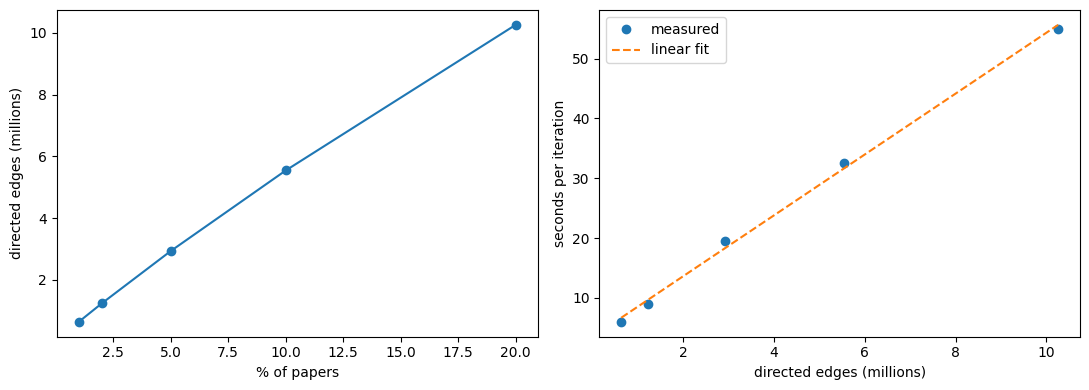

In [35]:
import numpy as np

m = scaling_df["edges"] / 1e6
t = scaling_df["time per iteration (s)"]
slope, intercept = np.polyfit(m, t, 1)
print(f"time per iteration ≈ {intercept:.1f} s + {slope:.2f} s per million edges")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(scaling_df["fraction"] * 100, m, "o-")
axes[0].set_xlabel("% of papers")
axes[0].set_ylabel("directed edges (millions)")
axes[1].plot(m, t, "o", label="measured")
axes[1].plot(m, intercept + slope * m, "--", label="linear fit")
axes[1].set_xlabel("directed edges (millions)")
axes[1].set_ylabel("seconds per iteration")
axes[1].legend()
plt.tight_layout()
plt.show()

Between 1% and 20% of the papers, the number of edges grows 16 times and the time of one iteration 9 times. The number of edges grows somewhat less than proportionally to the fraction of papers, because in larger samples repeated co-authorships collapse into a single edge. The time of one iteration is well described by a linear function of the number of edges: about 3.4 s of fixed overhead plus 5.1 s per million directed edges. The fixed part corresponds to costs that do not depend on the size of the data, such as scheduling the Spark jobs of each iteration; the variable part grows with the number of records produced and shuffled, in agreement with the communication cost discussed above.

The time to build the graph is about one minute up to 5% of the data, because it is dominated by reading the 5.4 GB file, and then grows with the number of edges.

In absolute terms the implementation is slow, about 5 seconds per million edges in local mode on a single Colab machine. A large part of this cost is likely due to the RDD API in PySpark, where every record passes between the JVM and the Python workers. No step of the computation gathers the data on a single node, so on a cluster the adjacency lists and the rank vector would be split across machines and the time per iteration is expected to decrease as more cores are added.

### Whole dataset

As a final check, the graph is built on the whole snapshot and two PageRank iterations are run. The number of partitions is increased so that each partition of the larger graph fits in memory. The measured time per iteration is compared with the prediction of the linear model.

In [36]:
NUM_PARTITIONS = 64  # more partitions for the full graph; used by pagerank from here on

t0 = time.time()
full_links = (build_edges(load_papers(1.0), MAX_AUTHORS)
              .groupByKey(NUM_PARTITIONS).mapValues(list)
              .persist(StorageLevel.MEMORY_AND_DISK))
n_full = full_links.count()
m_full = full_links.values().map(len).sum()
print(f"whole dataset: {n_full} authors, {m_full} directed edges, "
      f"graph built in {time.time() - t0:.0f} s")

predicted = intercept + slope * m_full / 1e6
t0 = time.time()
r, _ = pagerank(full_links, n_full, max_iter=2, tol=0)
measured = (time.time() - t0) / 2
print(f"time per iteration: measured {measured:.0f} s, predicted {predicted:.0f} s")
print(f"estimated time to convergence (55 iterations): {55 * measured / 3600:.1f} hours")

whole dataset: 1931713 authors, 37546302 directed edges, graph built in 849 s
time per iteration: measured 220 s, predicted 194 s
estimated time to convergence (55 iterations): 3.4 hours


The whole snapshot gives a graph of 1.93 million authors and 37.5 million directed edges, 3.7 times the edges of the 20% sample, built in about 14 minutes. One PageRank iteration takes 220 s against the 194 s predicted by the linear model, 13% more. The prediction extrapolates almost four times beyond the largest measured sample, so the agreement is reasonable; part of the difference may come from the larger number of partitions and from partitions written to disk.

Assuming the same number of iterations as on the sample (55, since the rate of convergence is set by β), running PageRank to convergence on the whole dataset would take about 3.4 hours on a single Colab machine. For this reason the analysis in the previous sections uses a 5% sample, while this section shows that the same code runs on the whole dataset, with a cost close to the one predicted from the smaller samples.

## Conclusions

- PageRank was computed with Spark RDDs on the co-authorship graph of a 5% sample of arXiv (340,220 authors, 2.9 million directed edges). The result agrees with networkx up to 4·10⁻¹⁰ per author, and the observed rate of convergence is close to β, as predicted by the convergence analysis.
- On an undirected co-authorship graph PageRank largely follows the number of co-authors, especially at the top of the ranking (weighted τ of 0.877 with the degree).
- The ranking is stable with respect to β and to the threshold on the number of authors per paper; β mainly changes the number of iterations.
- Topic-sensitive PageRank on mathematics brings to the top authors whom the general ranking places between position 184 and 2833.
- The time of one iteration grows linearly with the number of edges, and the code runs on the whole dataset (1.9 million authors, 37.5 million edges), where convergence would take about 3.4 hours on one Colab machine.

The main limitation is the identification of authors by name: homonyms are merged and name variants are split, which places common names at the top of both rankings. The results are also computed on a sample, and the RDD API of PySpark has a high cost per record.

**References**

- A. Rajaraman, J. Ullman, *Mining of Massive Datasets*, Cambridge University Press: chapter 2 (MapReduce, communication cost) and chapter 5 (PageRank, taxation, topic-sensitive PageRank).
- D. Malchiodi, course notebook "PageRank in Spark", Algorithms for Massive Data, Università degli Studi di Milano.
- J.-B. Lepidi, D. Malchiodi, "PageRank convergence proof", lecture notes for the course Algorithms for Massive Data, Università degli Studi di Milano.
- arXiv metadata snapshot, Cornell University, published on Kaggle (`Cornell-University/arxiv`).